# Assignment 03: Transfer Learning, Fine-Tuning, Hyperparameter Tuning, and Interpretability

**BRAC University, SICIP Batch 2**

**Student Name:** Rakib Hasan  
**Student ID:** 1000129213

**Task:** Classify user comments as toxic or not toxic using the Civil Comments dataset.  
**Model:** DistilBERT (distilbert-base-uncased)  
**Toxicity threshold:** 0.5 (scores >= 0.5 are toxic)

## Setup

In [2]:
# Install required packages (run once)
!pip install -q datasets transformers accelerate scikit-learn lime matplotlib pandas numpy

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
from sklearn.linear_model import LogisticRegression
from datasets import load_dataset
from transformers import DistilBertTokenizer, DistilBertModel, DistilBertForSequenceClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("torch:", torch.__version__)

Device: cuda
torch: 2.14.1+cu130


## 1. Load and Prepare the Civil Comments Dataset

In [4]:
# Load the Civil Comments dataset from Hugging Face
raw = load_dataset("google/civil_comments", split="train")
print("Full dataset size:", len(raw))

README.md:   0%|          | 0.00/7.73k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/1804874 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Full dataset size: 1804874


In [5]:
# Convert toxicity score to a binary label using threshold 0.5
TOXICITY_THRESHOLD = 0.5

# Take a random subset (10,000 samples) to keep training feasible
subset = raw.shuffle(seed=42).select(range(10000))

texts = subset["text"]
scores = np.array(subset["toxicity"])
labels = (scores >= TOXICITY_THRESHOLD).astype(int)

print("Subset size  :", len(texts))
print("Toxic        :", labels.sum())
print("Not toxic    :", (labels == 0).sum())
print("Toxic ratio  :", round(labels.mean(), 3))

Subset size  : 10000
Toxic        : 800
Not toxic    : 9200
Toxic ratio  : 0.08


In [6]:
# Train / validation / test split: 70% / 15% / 15%
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test = train_test_split(
    texts, labels, test_size=0.15, stratify=labels, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.176, stratify=y_temp, random_state=42  # 0.176 of 85% ~ 15%
)

print("Train:", len(X_train), "  Val:", len(X_val), "  Test:", len(X_test))

Train: 7004   Val: 1496   Test: 1500


## 2. Tokenization

In [7]:
MODEL_NAME = "distilbert-base-uncased"
tokenizer = DistilBertTokenizer.from_pretrained(MODEL_NAME)

class CommentDataset(Dataset):
    """Tokenize comments and pair them with labels."""
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt",
        )
        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[idx], dtype=torch.long),
        }

train_ds = CommentDataset(X_train, y_train, tokenizer)
val_ds   = CommentDataset(X_val, y_val, tokenizer)
test_ds  = CommentDataset(X_test, y_test, tokenizer)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=64)
test_loader  = DataLoader(test_ds, batch_size=64)

print("Loaders ready. Batches - train:", len(train_loader), " val:", len(val_loader), " test:", len(test_loader))

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Loaders ready. Batches - train: 219  val: 24  test: 24


---

## Part A: Transfer Learning (Frozen Feature Extraction) - Baseline

Load pretrained DistilBERT, freeze all its weights, extract the [CLS] embeddings, and train a logistic regression classifier on top. This is the baseline before any tuning.

In [8]:
# Load pretrained DistilBERT and freeze all weights
frozen_bert = DistilBertModel.from_pretrained(MODEL_NAME)
frozen_bert = frozen_bert.to(device)
frozen_bert.eval()

# Freeze every parameter
for param in frozen_bert.parameters():
    param.requires_grad = False

total_params = sum(p.numel() for p in frozen_bert.parameters())
trainable_params = sum(p.numel() for p in frozen_bert.parameters() if p.requires_grad)
print("Total parameters    :", total_params)
print("Trainable parameters:", trainable_params)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Total parameters    : 66362880
Trainable parameters: 0


In [9]:
def extract_cls_embeddings(model, loader):
    """Extract the [CLS] token embedding from the frozen model for every sample."""
    all_embeddings = []
    all_labels = []
    model.eval()
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            # The [CLS] token is the first token's hidden state
            cls_embedding = outputs.last_hidden_state[:, 0, :]
            all_embeddings.append(cls_embedding.cpu().numpy())
            all_labels.append(batch["label"].numpy())
    return np.concatenate(all_embeddings), np.concatenate(all_labels)

print("Extracting train embeddings...")
train_emb, train_lbl = extract_cls_embeddings(frozen_bert, train_loader)
print("Extracting val embeddings...")
val_emb, val_lbl = extract_cls_embeddings(frozen_bert, val_loader)
print("Extracting test embeddings...")
test_emb, test_lbl = extract_cls_embeddings(frozen_bert, test_loader)

print("Embedding shapes:", train_emb.shape, val_emb.shape, test_emb.shape)

Extracting train embeddings...
Extracting val embeddings...
Extracting test embeddings...
Embedding shapes: (7004, 768) (1496, 768) (1500, 768)


In [10]:
# Train a logistic regression on the frozen embeddings
start = time.time()
baseline_clf = LogisticRegression(max_iter=2000, random_state=42)
baseline_clf.fit(train_emb, train_lbl)
baseline_time = time.time() - start

# Evaluate on validation set
baseline_val_pred = baseline_clf.predict(val_emb)
baseline_val_acc = accuracy_score(val_lbl, baseline_val_pred)
baseline_val_f1 = f1_score(val_lbl, baseline_val_pred)

# Evaluate on test set
baseline_test_pred = baseline_clf.predict(test_emb)
baseline_test_acc = accuracy_score(test_lbl, baseline_test_pred)
baseline_test_f1 = f1_score(test_lbl, baseline_test_pred)

print("=== Frozen Baseline (Transfer Learning) ===")
print(f"Val  accuracy: {baseline_val_acc:.4f}   F1: {baseline_val_f1:.4f}")
print(f"Test accuracy: {baseline_test_acc:.4f}   F1: {baseline_test_f1:.4f}")
print(f"Time: {baseline_time:.1f}s")
print()
print("Test classification report:")
print(classification_report(test_lbl, baseline_test_pred, target_names=["Not Toxic", "Toxic"]))

=== Frozen Baseline (Transfer Learning) ===
Val  accuracy: 0.9211   F1: 0.2716
Test accuracy: 0.9153   F1: 0.2209
Time: 1.0s

Test classification report:
              precision    recall  f1-score   support

   Not Toxic       0.93      0.98      0.96      1380
       Toxic       0.42      0.15      0.22       120

    accuracy                           0.92      1500
   macro avg       0.67      0.57      0.59      1500
weighted avg       0.89      0.92      0.90      1500



In [11]:
# Store results for comparison
summary = {}
summary["Frozen baseline"] = {
    "val_acc": baseline_val_acc,
    "val_f1": baseline_val_f1,
    "test_acc": baseline_test_acc,
    "test_f1": baseline_test_f1,
    "time": baseline_time,
}

---

## Part B: Fine-Tuning

Unfreeze the entire DistilBERT model and fine-tune it end-to-end with a classification head. Compare with the frozen baseline.

In [12]:
def train_one_epoch(model, loader, optimizer, loss_fn):
    """Train for one epoch. Returns the average loss."""
    model.train()
    total_loss = 0
    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)


def evaluate(model, loader):
    """Evaluate and return accuracy, f1, and all predictions."""
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            preds = outputs.logits.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(batch["label"].numpy())
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    return acc, f1, np.array(all_preds), np.array(all_labels)

In [13]:
# Load a fresh DistilBERT for sequence classification (2 classes)
ft_model = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
)
ft_model = ft_model.to(device)

# All parameters are trainable (unfrozen)
ft_trainable = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
print("Trainable parameters:", ft_trainable)

# Fine-tuning settings
LEARNING_RATE = 2e-5
EPOCHS = 3

optimizer = torch.optim.AdamW(ft_model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)

print(f"\nFine-tuning for {EPOCHS} epochs at lr={LEARNING_RATE}...\n")
start = time.time()
for epoch in range(EPOCHS):
    train_loss = train_one_epoch(ft_model, train_loader, optimizer, None)
    val_acc, val_f1, _, _ = evaluate(ft_model, val_loader)
    print(f"Epoch {epoch+1}  loss: {train_loss:.4f}  val_acc: {val_acc:.4f}  val_f1: {val_f1:.4f}")
ft_time = time.time() - start

# Evaluate on test set
ft_test_acc, ft_test_f1, ft_test_preds, ft_test_labels = evaluate(ft_model, test_loader)
print(f"\n=== Fine-Tuned Model ===")
print(f"Test accuracy: {ft_test_acc:.4f}   F1: {ft_test_f1:.4f}")
print(f"Time: {ft_time:.1f}s")
print()
print(classification_report(ft_test_labels, ft_test_preds, target_names=["Not Toxic", "Toxic"]))

summary["Fine-tuned (lr=2e-5)"] = {
    "val_acc": val_acc,
    "val_f1": val_f1,
    "test_acc": ft_test_acc,
    "test_f1": ft_test_f1,
    "time": ft_time,
}

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 66955010

Fine-tuning for 3 epochs at lr=2e-05...

Epoch 1  loss: 0.2261  val_acc: 0.9398  val_f1: 0.5213
Epoch 2  loss: 0.1166  val_acc: 0.9405  val_f1: 0.5528
Epoch 3  loss: 0.0707  val_acc: 0.9345  val_f1: 0.5776

=== Fine-Tuned Model ===
Test accuracy: 0.9407   F1: 0.6079
Time: 258.2s

              precision    recall  f1-score   support

   Not Toxic       0.96      0.97      0.97      1380
       Toxic       0.64      0.57      0.61       120

    accuracy                           0.94      1500
   macro avg       0.80      0.77      0.79      1500
weighted avg       0.94      0.94      0.94      1500



---

## Part C: Hyperparameter Tuning

Search over learning rates and batch sizes to find the best fine-tuning configuration. We use a manual grid search to keep things transparent.

In [14]:
# Hyperparameter search space
search_space = {
    "learning_rate": [1e-5, 2e-5, 5e-5],
    "batch_size": [16, 32],
}

tuning_results = []

for lr in search_space["learning_rate"]:
    for bs in search_space["batch_size"]:
        print(f"\n--- lr={lr}, batch_size={bs} ---")

        # Rebuild loaders with this batch size
        t_loader = DataLoader(train_ds, batch_size=bs, shuffle=True)
        v_loader = DataLoader(val_ds, batch_size=64)

        # Fresh model each time
        model = DistilBertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
        model = model.to(device)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)

        start = time.time()
        best_val_f1 = 0
        for epoch in range(3):
            train_loss = train_one_epoch(model, t_loader, opt, None)
            v_acc, v_f1, _, _ = evaluate(model, v_loader)
            print(f"  Epoch {epoch+1}  loss: {train_loss:.4f}  val_acc: {v_acc:.4f}  val_f1: {v_f1:.4f}")
            if v_f1 > best_val_f1:
                best_val_f1 = v_f1
                best_val_acc = v_acc
        elapsed = time.time() - start

        tuning_results.append({
            "lr": lr,
            "batch_size": bs,
            "best_val_acc": best_val_acc,
            "best_val_f1": best_val_f1,
            "time": elapsed,
        })

        # Keep the best model
        if best_val_f1 >= max(r["best_val_f1"] for r in tuning_results):
            best_model = model
            best_lr = lr
            best_bs = bs

tuning_df = pd.DataFrame(tuning_results).sort_values("best_val_f1", ascending=False)
print("\n=== Tuning Results ===")
print(tuning_df.to_string(index=False))


--- lr=1e-05, batch_size=16 ---


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1  loss: 0.2359  val_acc: 0.9385  val_f1: 0.5446
  Epoch 2  loss: 0.1270  val_acc: 0.9378  val_f1: 0.5419
  Epoch 3  loss: 0.0780  val_acc: 0.9392  val_f1: 0.5806

--- lr=1e-05, batch_size=32 ---


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (9 outputs left out)

  Epoch 1  loss: 0.2170  val_acc: 0.9358  val_f1: 0.4839
  Epoch 2  loss: 0.1172  val_acc: 0.9218  val_f1: 0.5185
  Epoch 3  loss: 0.0541  val_acc: 0.9338  val_f1: 0.5217

--- lr=5e-05, batch_size=32 ---


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1  loss: 0.2114  val_acc: 0.9398  val_f1: 0.4886
  Epoch 2  loss: 0.1099  val_acc: 0.9325  val_f1: 0.5511
  Epoch 3  loss: 0.0577  val_acc: 0.9238  val_f1: 0.5512

=== Tuning Results ===
     lr  batch_size  best_val_acc  best_val_f1       time
0.00002          32      0.934492     0.604839 260.628343
0.00001          16      0.939171     0.580645 279.987236
0.00002          16      0.933824     0.560000 279.923295
0.00001          32      0.930481     0.559322 260.859043
0.00005          32      0.923797     0.551181 261.003161
0.00005          16      0.933824     0.521739 280.028693


In [15]:
# Evaluate the best tuned model on the test set
tuned_test_acc, tuned_test_f1, tuned_test_preds, tuned_test_labels = evaluate(best_model, test_loader)

print(f"\n=== Best Tuned Model (lr={best_lr}, bs={best_bs}) ===")
print(f"Test accuracy: {tuned_test_acc:.4f}   F1: {tuned_test_f1:.4f}")
print()
print(classification_report(tuned_test_labels, tuned_test_preds, target_names=["Not Toxic", "Toxic"]))

summary[f"Tuned (lr={best_lr}, bs={best_bs})"] = {
    "val_acc": best_val_acc,
    "val_f1": best_val_f1,
    "test_acc": tuned_test_acc,
    "test_f1": tuned_test_f1,
    "time": 0,
}


=== Best Tuned Model (lr=2e-05, bs=32) ===
Test accuracy: 0.9300   F1: 0.5679

              precision    recall  f1-score   support

   Not Toxic       0.96      0.96      0.96      1380
       Toxic       0.56      0.57      0.57       120

    accuracy                           0.93      1500
   macro avg       0.76      0.77      0.76      1500
weighted avg       0.93      0.93      0.93      1500



---

## Part D: Comparison Table

Compare all three approaches side by side.

=== Final Comparison ===
                         Val Accuracy  Val F1  Test Accuracy  Test F1
Frozen baseline                0.9211  0.2716         0.9153   0.2209
Fine-tuned (lr=2e-5)           0.9345  0.5776         0.9407   0.6079
Tuned (lr=2e-05, bs=32)        0.9238  0.5512         0.9300   0.5679


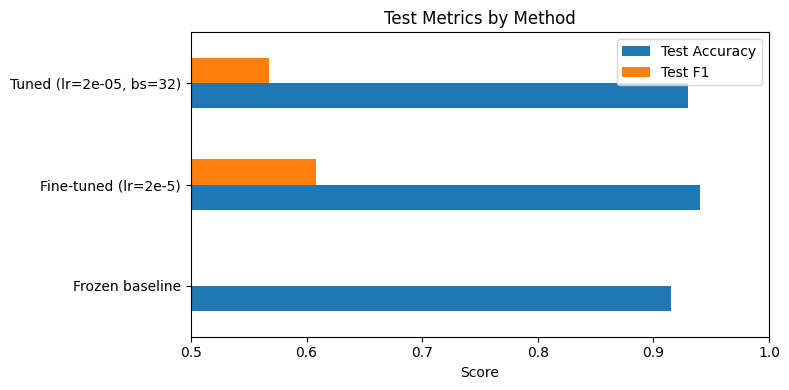

In [16]:
import matplotlib.pyplot as plt

comp_df = pd.DataFrame(summary).T[["val_acc", "val_f1", "test_acc", "test_f1"]]
comp_df.columns = ["Val Accuracy", "Val F1", "Test Accuracy", "Test F1"]
print("=== Final Comparison ===")
print(comp_df.round(4).to_string())

# Bar chart
comp_df[["Test Accuracy", "Test F1"]].plot(
    kind="barh",
    figsize=(8, 4),
    xlim=(0.5, 1.0),
)
plt.title("Test Metrics by Method")
plt.xlabel("Score")
plt.tight_layout()
plt.savefig("comparison_chart.png", dpi=150)
plt.show()

---

## Part E: Real-World Text Test

Test the best model on hand-written comments that were not in the dataset.

In [17]:
real_world_texts = [
    "This article is really well written, thanks for sharing.",
    "You are such an idiot, nobody cares about your stupid opinion.",
    "I respectfully disagree with the author's conclusion.",
    "Shut up you worthless piece of garbage, go die.",
    "Great point! I hadn't thought about it that way before.",
    "These people are all criminals and should be locked up forever.",
    "The data clearly supports the opposite conclusion.",
    "What a moronic take. Only a complete fool would believe this.",
]

expected = ["Not Toxic", "Toxic", "Not Toxic", "Toxic", "Not Toxic", "Toxic", "Not Toxic", "Toxic"]

best_model.eval()
print("=== Real-World Text Predictions ===\n")
for text, exp in zip(real_world_texts, expected):
    encoding = tokenizer(
        text,
        truncation=True,
        padding="max_length",
        max_length=128,
        return_tensors="pt",
    )
    with torch.no_grad():
        logits = best_model(
            input_ids=encoding["input_ids"].to(device),
            attention_mask=encoding["attention_mask"].to(device),
        ).logits
    probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
    pred_label = "Toxic" if probs[1] > 0.5 else "Not Toxic"
    match = "correct" if pred_label == exp else "WRONG"
    print(f"Text    : {text}")
    print(f"Predicted: {pred_label} (toxic prob: {probs[1]:.3f})  Expected: {exp}  [{match}]")
    print()

=== Real-World Text Predictions ===

Text    : This article is really well written, thanks for sharing.
Predicted: Not Toxic (toxic prob: 0.004)  Expected: Not Toxic  [correct]

Text    : You are such an idiot, nobody cares about your stupid opinion.
Predicted: Toxic (toxic prob: 0.985)  Expected: Toxic  [correct]

Text    : I respectfully disagree with the author's conclusion.
Predicted: Not Toxic (toxic prob: 0.003)  Expected: Not Toxic  [correct]

Text    : Shut up you worthless piece of garbage, go die.
Predicted: Toxic (toxic prob: 0.984)  Expected: Toxic  [correct]

Text    : Great point! I hadn't thought about it that way before.
Predicted: Not Toxic (toxic prob: 0.003)  Expected: Not Toxic  [correct]

Text    : These people are all criminals and should be locked up forever.
Predicted: Toxic (toxic prob: 0.926)  Expected: Toxic  [correct]

Text    : The data clearly supports the opposite conclusion.
Predicted: Not Toxic (toxic prob: 0.002)  Expected: Not Toxic  [correct]

Text  

---

## Part F: Interpretability with LIME

Explain individual predictions using LIME (Local Interpretable Model-agnostic Explanations). LIME builds a simple, interpretable model around each prediction to show which words pushed the decision toward toxic or not toxic.

In [18]:
from lime.lime_text import LimeTextExplainer

def predict_proba_for_lime(texts):
    """Wrapper that LIME calls: takes a list of strings, returns probabilities."""
    best_model.eval()
    all_probs = []
    # Process in batches of 32 for efficiency
    for i in range(0, len(texts), 32):
        batch_texts = texts[i:i+32]
        encoding = tokenizer(
            list(batch_texts),
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt",
        )
        with torch.no_grad():
            logits = best_model(
                input_ids=encoding["input_ids"].to(device),
                attention_mask=encoding["attention_mask"].to(device),
            ).logits
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        all_probs.append(probs)
    return np.concatenate(all_probs)

lime_explainer = LimeTextExplainer(class_names=["Not Toxic", "Toxic"], random_state=42)
print("LIME explainer ready.")

LIME explainer ready.


In [19]:
# Explain 4 selected predictions: 2 toxic, 2 not toxic
texts_to_explain = [
    "You are such an idiot, nobody cares about your stupid opinion.",
    "Shut up you worthless piece of garbage, go die.",
    "This article is really well written, thanks for sharing.",
    "I respectfully disagree with the author's conclusion.",
]

for text in texts_to_explain:
    explanation = lime_explainer.explain_instance(
        text,
        predict_proba_for_lime,
        num_features=10,
        num_samples=1000,
    )

    probs = predict_proba_for_lime([text])[0]
    pred = "Toxic" if probs[1] > 0.5 else "Not Toxic"

    print(f"\nText: \"{text}\"")
    print(f"Prediction: {pred} (toxic prob: {probs[1]:.3f})")
    print(f"Local surrogate R2: {explanation.score:.3f}")
    print("Top contributing words:")
    for word, weight in explanation.as_list():
        direction = "toward Toxic" if weight > 0 else "toward Not Toxic"
        print(f"  {weight:+.4f}  {word:20s}  ({direction})")
    print("-" * 60)


Text: "You are such an idiot, nobody cares about your stupid opinion."
Prediction: Toxic (toxic prob: 0.985)
Local surrogate R2: 0.565
Top contributing words:
  +0.3501  idiot                 (toward Toxic)
  +0.3184  stupid                (toward Toxic)
  +0.0246  such                  (toward Toxic)
  -0.0230  an                    (toward Not Toxic)
  -0.0155  about                 (toward Not Toxic)
  -0.0138  opinion               (toward Not Toxic)
  +0.0132  are                   (toward Toxic)
  -0.0088  your                  (toward Not Toxic)
  +0.0085  nobody                (toward Toxic)
  -0.0029  You                   (toward Not Toxic)
------------------------------------------------------------

Text: "Shut up you worthless piece of garbage, go die."
Prediction: Toxic (toxic prob: 0.984)
Local surrogate R2: 0.398
Top contributing words:
  +0.1533  garbage               (toward Toxic)
  +0.1528  worthless             (toward Toxic)
  +0.0713  die                   (towa

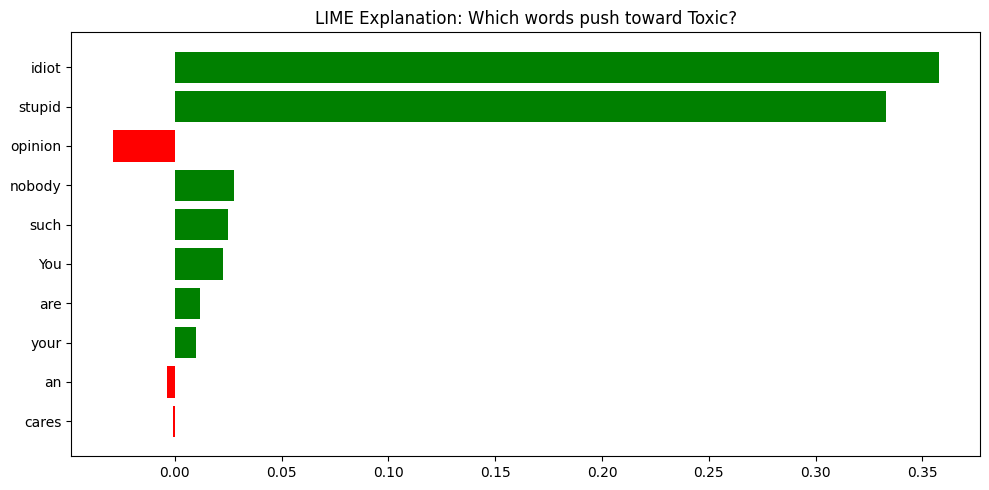

In [20]:
# Visual explanation for one example
example_text = "You are such an idiot, nobody cares about your stupid opinion."
explanation = lime_explainer.explain_instance(
    example_text,
    predict_proba_for_lime,
    num_features=10,
    num_samples=1000,
)

fig = explanation.as_pyplot_figure()
fig.set_size_inches(10, 5)
plt.title("LIME Explanation: Which words push toward Toxic?")
plt.tight_layout()
plt.savefig("lime_explanation.png", dpi=150)
plt.show()

---

## Part G: Confusion Matrix

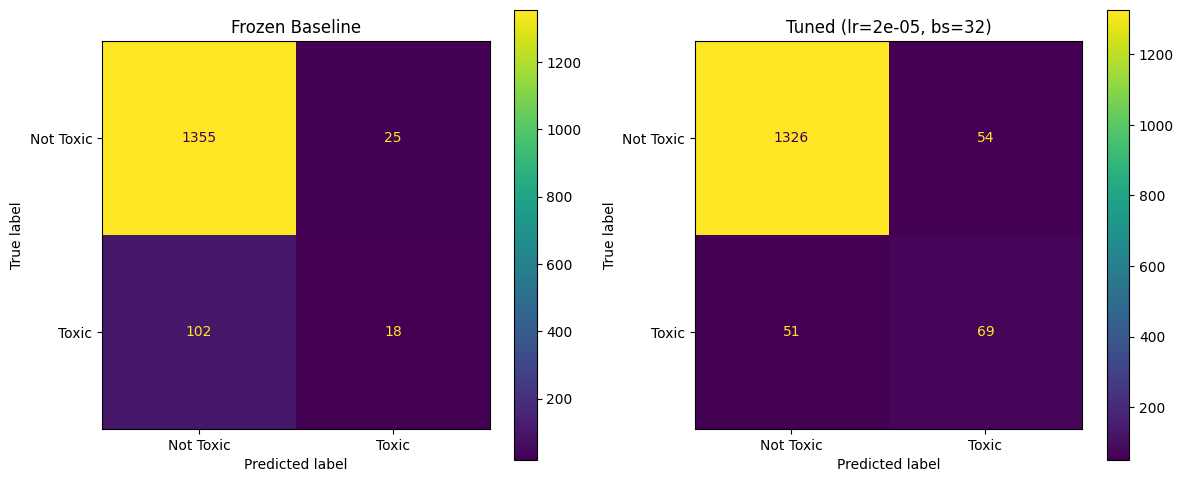

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Baseline confusion matrix
ConfusionMatrixDisplay.from_predictions(
    test_lbl, baseline_test_pred,
    display_labels=["Not Toxic", "Toxic"],
    ax=axes[0],
)
axes[0].set_title("Frozen Baseline")

# Tuned model confusion matrix
ConfusionMatrixDisplay.from_predictions(
    tuned_test_labels, tuned_test_preds,
    display_labels=["Not Toxic", "Toxic"],
    ax=axes[1],
)
axes[1].set_title(f"Tuned (lr={best_lr}, bs={best_bs})")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

In [22]:
from google.colab import files
files.download('comparison_chart.png')
files.download('lime_explanation.png')
files.download('confusion_matrices.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

**End of Assignment 03.** Restart kernel and run all cells to confirm everything works.